In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler

In [ ]:
df = pd.read_csv('base_rh_bruta.csv', sep=';')

In [ ]:
print(df.head())
print('Linhas:', len(df))
print('Colunas:', df.columns.tolist())
df.info()
print(df.isnull().sum())
print('Linhas duplicadas:', df.duplicated().sum())

   id_funcionario data_admissao data_desligamento status tipo_desligamento  \
0           10858    02/10/2020               NaN  Ativo               NaN   
1           11926    2025-05-24               NaN  Ativo               NaN   
2           11607    11/01/2023               NaN  Ativo               NaN   
3           12621    04/11/2024               NaN  Ativo               NaN   
4           12235    16/02/2026               NaN  Ativo               NaN   

  motivo_desligamento         cargo departamento          cidade  gestor_id  \
0                 NaN   Analista Jr    Operações  Rio de Janeiro       20.0   
1                 NaN  ANALISTA JR            TI       Sao Paulo       29.0   
2                 NaN   analista pl          MKT        Curitiba       10.0   
3                 NaN   Analista Jr    Marketing  Belo Horizonte       44.0   
4                 NaN   Analista Pl           TI  Belo Horizonte       54.0   

   ... num_dependentes  distancia_casa_trabalho_km model

In [ ]:
# Gênero: padroniza as grafias; nulo ou valor desconhecido vira 'Não informado'
# (não se preenche com a moda: isso inventaria o gênero de pessoas reais)
df['genero'] = (
    df['genero'].astype('string').str.strip().str.lower()
    .map({'m': 'Masculino', 'masculino': 'Masculino',
          'f': 'Feminino', 'feminino': 'Feminino'})
    .fillna('Não informado')
)
print(df['genero'].value_counts())

# gestor_id: 0 = sem gestor identificado
df['gestor_id'] = df['gestor_id'].fillna(0)

# Categóricas: 'não informado' mantém a categoria visível nas análises
for col in ['escolaridade', 'estado_civil', 'modelo_trabalho']:
    df[col] = df[col].fillna('não informado')

# Dependentes: nulo tratado como 0 e convertido para inteiro
df['num_dependentes'] = df['num_dependentes'].fillna(0).astype(int)

# Horas extras, absenteísmo e meses desde a última promoção:
# NÃO imputados. Zero significaria "não fez hora extra / acabou de ser promovido",
# o que pode não ser verdade e criaria relações falsas. Ficam como NaN.
for col in ['horas_extras_mes', 'absenteismo_dias_12m',
            'meses_desde_ultima_promocao', 'distancia_casa_trabalho_km']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

genero
Masculino        1550
Feminino         1357
Não informado     121
Name: count, dtype: int64


In [ ]:
# Textos inválidos (ex.: '-') viram NaN; não se imputa
df['nota_avaliacao_desempenho'] = pd.to_numeric(df['nota_avaliacao_desempenho'], errors='coerce')

In [ ]:
# A flag marca quem respondeu a pesquisa. Nulo = não respondeu.
df['satisfacao_clima_0a10'] = pd.to_numeric(df['satisfacao_clima_0a10'], errors='coerce')
df['respondeu_clima'] = df['satisfacao_clima_0a10'].notna()
print('Responderam:', df['respondeu_clima'].sum(),
      '| Não responderam:', (~df['respondeu_clima']).sum())

Responderam: 2361 | Não responderam: 667


In [ ]:
# Remove R$ e espaços. Quando há vírgula (formato brasileiro), remove o ponto de
# milhar e troca a vírgula por ponto. Valores sem vírgula (ex.: '5190.37') ficam como estão,
# assim o ponto decimal não é apagado por engano.
s = df['salario_base'].astype(str).str.replace(r'[R$\s]', '', regex=True)
tem_virgula = s.str.contains(',')
s = s.where(~tem_virgula,
            s.str.replace('.', '', regex=False).str.replace(',', '.', regex=False))
df['salario_base'] = pd.to_numeric(s, errors='coerce')   # NaN fica NaN

print('Salários inválidos/nulos:', df['salario_base'].isna().sum())
print(df['salario_base'].describe())   # confira se min/max são plausíveis

Salários inválidos/nulos: 92
count      2936.000000
mean      11319.342197
std        8001.319114
min           0.000000
25%        7464.617500
50%        9767.470000
75%       13358.797500
max      250000.000000
Name: salario_base, dtype: float64


In [ ]:
df['data_admissao'] = pd.to_datetime(df['data_admissao'], dayfirst=True, errors='coerce')
df['data_desligamento'] = pd.to_datetime(df['data_desligamento'], dayfirst=True, errors='coerce')

# Nulo em data_desligamento = ainda ativo
df['desligado'] = df['data_desligamento'].notna()

# Tempo de casa (anos): até a saída para desligados; até a data de referência para ativos
data_ref = max(df['data_admissao'].max(), df['data_desligamento'].max())
fim_vinculo = df['data_desligamento'].fillna(data_ref)
df['tempo_casa_anos'] = (fim_vinculo - df['data_admissao']).dt.days / 365.25

print('Admissões sem data (ficam fora dos cálculos de tempo de casa):',
      df['data_admissao'].isna().sum())
print('Desligados:', df['desligado'].sum(), '| Ativos:', (~df['desligado']).sum())

# Datas inconsistentes: desligamento antes da admissão
inconsistentes = df[df['data_desligamento'] < df['data_admissao']]
print('Datas inconsistentes (desligamento < admissão):', len(inconsistentes))

Admissões sem data (ficam fora dos cálculos de tempo de casa): 362
Desligados: 1016 | Ativos: 2012
Datas inconsistentes (desligamento < admissão): 7


In [ ]:
print('Data de admissão mais frequente:', df['data_admissao'].mode()[0])
print('Admissões por ano:')
print(df['data_admissao'].dt.year.value_counts().sort_index())

# Quantidade de cargos diferentes por cidade
print(df.groupby('cidade')['cargo'].nunique().sort_values(ascending=False))

Data de admissão mais frequente: 2022-03-09 00:00:00
Admissões por ano:
data_admissao
2015.0     58
2016.0    109
2017.0    140
2018.0    210
2019.0    224
2020.0    244
2021.0    252
2022.0    308
2023.0    327
2024.0    334
2025.0    377
2026.0     83
Name: count, dtype: int64
cidade
Belo Horizonte    19
Porto Alegre      19
São Paulo         19
Rio de Janeiro    19
Curitiba          18
Campinas          18
Rio               17
curitiba          17
S. Paulo          17
Sao Paulo         16
BH                16
RJ                16
campinas          15
SP                15
POA               14
são paulo         10
Name: cargo, dtype: int64


In [ ]:
# Nulos esperados: colunas de desligamento (ativos) e as colunas NÃO imputadas
print(df.isnull().sum())

# ==============================================================================
# ANÁLISE
# ==============================================================================

id_funcionario                    0
data_admissao                   362
data_desligamento              2012
status                            0
tipo_desligamento              1872
motivo_desligamento            2104
cargo                             0
departamento                      0
cidade                            0
gestor_id                         0
genero                            0
idade                             0
escolaridade                      0
estado_civil                      0
num_dependentes                   0
distancia_casa_trabalho_km      542
modelo_trabalho                   0
horas_extras_mes                240
absenteismo_dias_12m            211
treinamentos_12m                  0
meses_desde_ultima_promocao     456
nota_avaliacao_desempenho       362
satisfacao_clima_0a10           667
salario_base                     92
respondeu_clima                   0
desligado                         0
tempo_casa_anos                 362
dtype: int64


      desligamentos  headcount_medio  turnover_%
ano                                             
2015              4        21.750000   18.390805
2016             18        97.750000   18.414322
2017             26       208.333333   12.480000
2018             43       350.500000   12.268188
2019             72       514.666667   13.989637
2020             89       677.625000   13.134108
2021             81       844.458333    9.591948
2022            106      1063.125000    9.970606
2023            136      1252.875000   10.855033
2024            163      1455.041667   11.202428
2025            183      1653.250000   11.069106
2026             89      1796.583333    4.953848


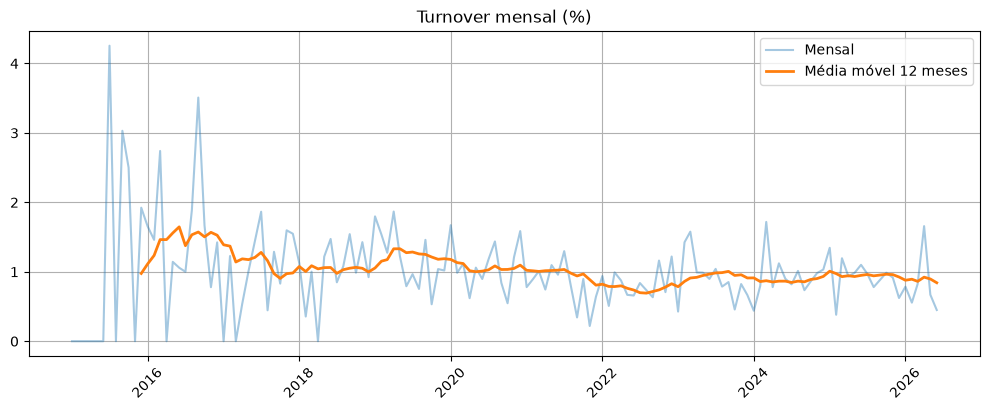

In [ ]:
# Turnover (%) = desligamentos no período / headcount médio do período * 100
inicio = df['data_admissao'].min()
fim = max(df['data_admissao'].max(), df['data_desligamento'].max())

linhas = []
for m in pd.period_range(inicio, fim, freq='M'):
    ini, final = m.start_time, m.end_time

    hc_inicio = ((df['data_admissao'] < ini) &
                 (df['data_desligamento'].isna() | (df['data_desligamento'] >= ini))).sum()
    hc_fim = ((df['data_admissao'] <= final) &
              (df['data_desligamento'].isna() | (df['data_desligamento'] > final))).sum()
    saidas = df['data_desligamento'].between(ini, final).sum()

    linhas.append({
        'periodo': m,
        'ano': m.year,
        'mes': m.month,
        'desligamentos': saidas,
        'headcount_medio': (hc_inicio + hc_fim) / 2,
    })

turnover_mensal = pd.DataFrame(linhas)
turnover_mensal['turnover_%'] = (
    turnover_mensal['desligamentos'] / turnover_mensal['headcount_medio'] * 100
)
# Média móvel de 12 meses: suaviza oscilações e mostra a tendência
turnover_mensal['media_movel_12m'] = turnover_mensal['turnover_%'].rolling(12).mean()

turnover_anual = turnover_mensal.groupby('ano').agg(
    desligamentos=('desligamentos', 'sum'),
    headcount_medio=('headcount_medio', 'mean'),
)
turnover_anual['turnover_%'] = (
    turnover_anual['desligamentos'] / turnover_anual['headcount_medio'] * 100
)
print(turnover_anual)
# Atenção: o último ano pode estar incompleto e aparecer artificialmente menor.

x = turnover_mensal['periodo'].dt.to_timestamp()
plt.figure(figsize=(10, 4))
plt.plot(x, turnover_mensal['turnover_%'], alpha=0.4, label='Mensal')
plt.plot(x, turnover_mensal['media_movel_12m'], linewidth=2, label='Média móvel 12 meses')
plt.title('Turnover mensal (%)')
plt.legend()
plt.tight_layout()
plt.grid()
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Turnover do grupo = desligados / total de pessoas que já passaram pelo grupo
for col in ['departamento', 'cargo', 'cidade']:
    r = df.groupby(col)['desligado'].agg(desligados='sum', total='count')
    r['turnover_%'] = r['desligados'] / r['total'] * 100
    # Evita distorção de grupos muito pequenos (1 de 2 = 50%)
    r = r[r['total'] >= 10]
    print(f'\nMaior turnover por {col}:')
    print(r.sort_values('turnover_%', ascending=False).head(10))


Maior turnover por departamento:
                          desligados  total  turnover_%
departamento                                           
ti                                28     70   40.000000
Tecnologia da Informação          26     66   39.393939
T.I.                              28     73   38.356164
Operacoes                         34     92   36.956522
financeiro                        19     52   36.538462
MKT                               14     39   35.897436
Marketing                         64    180   35.555556
rh                                11     31   35.483871
Financeiro                       106    303   34.983498
Operações                        167    478   34.937238

Maior turnover por cargo:
                 desligados  total  turnover_%
cargo                                         
Analista Senior          21     53   39.622642
Coord.                   14     36   38.888889
coordenador              15     39   38.461538
analista jr              21     

In [ ]:
# Aqui só entram os desligados. Nulo nessas colunas, para um desligado,
# é de fato dado faltante e pode virar 'não informado'.
desligados = df[df['desligado']].copy()
desligados['tipo_desligamento'] = desligados['tipo_desligamento'].fillna('não informado')
desligados['motivo_desligamento'] = desligados['motivo_desligamento'].fillna('não informado')

print('\nProporção por tipo de desligamento (%):')
print(desligados['tipo_desligamento'].value_counts(normalize=True) * 100)

print('\nMotivos dentro de cada tipo (%):')
print(desligados.groupby('tipo_desligamento')['motivo_desligamento']
      .value_counts(normalize=True) * 100)

print('\nPrincipais motivos no geral (%):')
print(desligados['motivo_desligamento'].value_counts(normalize=True).head(10) * 100)


Proporção por tipo de desligamento (%):
tipo_desligamento
Voluntário       69.783465
Involuntário     29.035433
não informado     1.181102
Name: proportion, dtype: float64

Motivos dentro de cada tipo (%):
tipo_desligamento  motivo_desligamento    
Involuntário       Baixo desempenho            35.254237
                   Reestruturação              29.830508
                   não informado               22.033898
                   Justa causa                 12.881356
Voluntário         Melhor proposta externa     21.297602
                   não informado               19.746121
                   Falta de crescimento        19.181946
                   Insatisfação com gestor     18.053597
                   Motivos pessoais            12.270804
                   Mudança de carreira          9.449929
não informado      não informado              100.000000
Name: proportion, dtype: float64

Principais motivos no geral (%):
motivo_desligamento
não informado              21.358268

In [ ]:
desligados['tempo_casa_dias'] = (
    desligados['data_desligamento'] - desligados['data_admissao']
).dt.days

# Registros sem data de admissão (ou datas inconsistentes) ficam fora da conta
validos = desligados[desligados['tempo_casa_dias'].notna() & (desligados['tempo_casa_dias'] >= 0)].copy()
validos['tipo_turnover'] = np.where(validos['tempo_casa_dias'] < 365, 'Precoce', 'Normal')

precoce = validos[validos['tipo_turnover'] == 'Precoce']
print(f'\nSaíram com menos de 1 ano de casa: {len(precoce)} '
      f'({len(precoce) / len(validos) * 100:.1f}% dos desligados com datas válidas)')

# Onde o turnover precoce se concentra
print(precoce['departamento'].value_counts().head(5))


Saíram com menos de 1 ano de casa: 282 (31.9% dos desligados com datas válidas)
departamento
TI            59
Comercial     52
Operações     35
Financeiro    35
RH            16
Name: count, dtype: int64


                       total  desligados  turnover_%
satisfacao_clima_0a10                               
0.0                        1           1       100.0
1.0                        9           7        77.8
2.0                       34          20        58.8
3.0                       99          52        52.5
4.0                      227         100        44.1
5.0                      376         142        37.8
6.0                      462         131        28.4
7.0                      462         104        22.5
8.0                      354          66        18.6
9.0                      219          36        16.4
10.0                     118          10         8.5

Respondeu (True) x Não respondeu (False):
                 total  desligados  turnover_%
respondeu_clima                               
False              667         347        52.0
True              2361         669        28.3


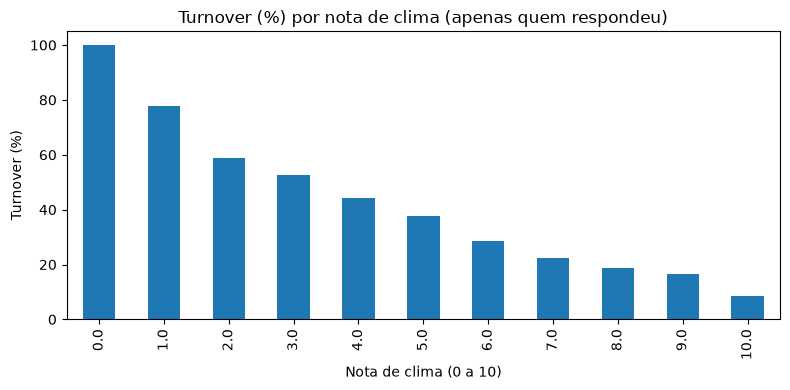

In [ ]:
# 6.1 Taxa de desligamento por nota (só quem respondeu)
clima = (
    df[df['respondeu_clima']]
    .groupby('satisfacao_clima_0a10')['desligado']
    .agg(total='count', desligados='sum')
)
clima['turnover_%'] = (clima['desligados'] / clima['total'] * 100).round(1)
print(clima)

# 6.2 Respondeu x não respondeu
resp = df.groupby('respondeu_clima')['desligado'].agg(total='count', desligados='sum')
resp['turnover_%'] = (resp['desligados'] / resp['total'] * 100).round(1)
print('\nRespondeu (True) x Não respondeu (False):')
print(resp)

clima['turnover_%'].plot(kind='bar', figsize=(8, 4))
plt.title('Turnover (%) por nota de clima (apenas quem respondeu)')
plt.xlabel('Nota de clima (0 a 10)')
plt.ylabel('Turnover (%)')
plt.tight_layout()
plt.show()

desligado        False  True 
modelo_trabalho              
Híbrido           67.8   32.2
Presencial        63.7   36.3
Remoto            69.2   30.8
não informado     65.6   34.4

Tamanho de cada grupo:
modelo_trabalho
Híbrido          1311
Presencial       1127
Remoto            500
não informado      90
Name: count, dtype: int64


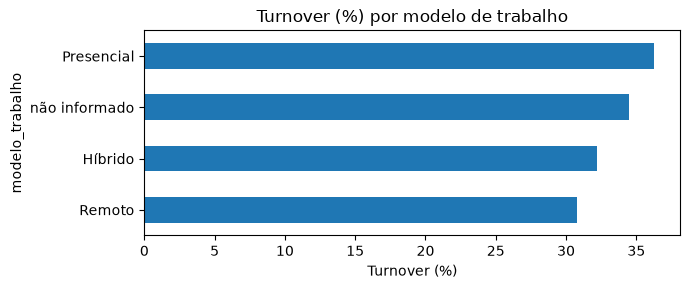

In [ ]:
# Proporção dentro de cada modelo (comparável entre grupos de tamanhos diferentes)
modelo = pd.crosstab(df['modelo_trabalho'], df['desligado'], normalize='index') * 100
print(modelo.round(1))
print('\nTamanho de cada grupo:')
print(df['modelo_trabalho'].value_counts())

if True in modelo.columns:
    modelo[True].sort_values().plot(kind='barh', figsize=(7, 3))
    plt.title('Turnover (%) por modelo de trabalho')
    plt.xlabel('Turnover (%)')
    plt.tight_layout()
    plt.show()

In [ ]:
# Só Masculino/Feminino com salário válido (sem imputação)
sub = df[df['genero'].isin(['Masculino', 'Feminino'])].dropna(subset=['salario_base']).copy()
print('Linhas usadas:', len(sub), 'de', len(df))

# 8.1 Diferença bruta
bruta = sub.groupby('genero')['salario_base'].agg(['count', 'mean', 'median'])
print('=== DIFERENÇA BRUTA ===')
print(bruta.round(2))
dif_bruta = (bruta.loc['Masculino', 'mean'] / bruta.loc['Feminino', 'mean'] - 1) * 100
print(f'Diferença bruta (média): homens ganham {dif_bruta:.2f}% em relação às mulheres')

Linhas usadas: 2820 de 3028
=== DIFERENÇA BRUTA ===
           count      mean   median
genero                             
Feminino    1315  11229.71  9728.86
Masculino   1505  11435.04  9821.32
Diferença bruta (média): homens ganham 1.83% em relação às mulheres


In [ ]:
# Só Masculino/Feminino com salário válido (sem imputação)
sub = df[df['genero'].isin(['Masculino', 'Feminino'])].dropna(subset=['salario_base']).copy()
print('Linhas usadas:', len(sub), 'de', len(df))

# 8.1 Diferença bruta
bruta = sub.groupby('genero')['salario_base'].agg(['count', 'mean', 'median'])
print('=== DIFERENÇA BRUTA ===')
print(bruta.round(2))
dif_bruta = (bruta.loc['Masculino', 'mean'] / bruta.loc['Feminino', 'mean'] - 1) * 100
print(f'Diferença bruta (média): homens ganham {dif_bruta:.2f}% em relação às mulheres')

Linhas usadas: 2820 de 3028
=== DIFERENÇA BRUTA ===
           count      mean   median
genero                             
Feminino    1315  11229.71  9728.86
Masculino   1505  11435.04  9821.32
Diferença bruta (média): homens ganham 1.83% em relação às mulheres


In [ ]:
fatores_controle = ['cargo', 'departamento', 'escolaridade']
g = (
    sub.groupby(fatores_controle + ['genero'])['salario_base']
    .agg(['count', 'mean'])
    .unstack('genero')
    .dropna()
)
# Exige pelo menos 5 pessoas de cada gênero em cada combinação
g = g[(g[('count', 'Masculino')] >= 5) & (g[('count', 'Feminino')] >= 5)]

if len(g) == 0:
    print('Nenhuma combinação com pelo menos 5 pessoas de cada gênero.')
else:
    m = g[('mean', 'Masculino')]
    f = g[('mean', 'Feminino')]
    dif = (m / f - 1) * 100
    peso = g[('count', 'Masculino')] + g[('count', 'Feminino')]
    dif_pond = np.average(dif, weights=peso)
    print(f'Combinações comparáveis: {len(g)}')
    print(f'Diferença média ponderada pelo tamanho do grupo: {dif_pond:.2f}%')
    print(dif.describe().round(2))

Combinações comparáveis: 46
Diferença média ponderada pelo tamanho do grupo: 1.36%
count    46.00
mean      1.33
std       4.89
min     -15.26
25%      -0.96
50%       1.46
75%       3.45
max      14.10
dtype: float64


In [ ]:
# (experiência aproximada por idade e tempo de casa; são proxies)
cat = ['genero', 'cargo', 'departamento', 'escolaridade']
num = ['idade', 'tempo_casa_anos']
dados = sub[cat + num + ['salario_base']].dropna()
dados = dados[dados['salario_base'] > 0]
print('Linhas na regressão:', len(dados), 'de', len(sub))

X = pd.get_dummies(dados[cat + num], columns=cat, drop_first=True, dtype=float)
y = np.log(dados['salario_base'])

reg = LinearRegression().fit(X, y)
coef_genero = pd.Series(reg.coef_, index=X.columns)['genero_Masculino']
dif_controlada = (np.exp(coef_genero) - 1) * 100

print(f'\nDiferença controlada (regressão): homens ganham {dif_controlada:.2f}% '
      f'em relação às mulheres, com cargo, departamento, escolaridade, idade e tempo de casa iguais.')

Linhas na regressão: 2481 de 2820

Diferença controlada (regressão): homens ganham 1.96% em relação às mulheres, com cargo, departamento, escolaridade, idade e tempo de casa iguais.

Diferença controlada (regressão): homens ganham 1.96% em relação às mulheres, com cargo, departamento, escolaridade, idade e tempo de casa iguais.


In [ ]:
def descreve(dif):
    if abs(dif) < 1:
        return 'praticamente não há diferença (menos de 1%)'
    quem = 'homens ganham mais' if dif > 0 else 'mulheres ganham mais'
    return f'{quem} ({abs(dif):.1f}%)'

print('Bruta:      ', descreve(dif_bruta))
print('Controlada: ', descreve(dif_controlada))
# Se a bruta for grande e a controlada pequena, a diferença se explica pela composição
# (cargos, escolaridade etc.). Se a controlada continua relevante, ela persiste.
# Obs.: sem p-valor, não dá para afirmar significância estatística.

Bruta:       homens ganham mais (1.8%)
Controlada:  homens ganham mais (2.0%)


In [ ]:
cols_9 = ['distancia_casa_trabalho_km', 'horas_extras_mes', 'meses_desde_ultima_promocao']

# 9.1 Desligados x ativos
print(df.groupby('desligado')[cols_9].agg(['count', 'mean', 'median']).round(2))

# 9.2 Taxa de saída por quartil
for c in cols_9:
    faixas = pd.qcut(df[c], q=4, duplicates='drop')
    taxa = df.groupby(faixas, observed=True)['desligado'].agg(total='count', turnover='mean')
    taxa['turnover'] = (taxa['turnover'] * 100).round(1)
    print(f'\n{c}')
    print(taxa)

          distancia_casa_trabalho_km               horas_extras_mes         \
                               count   mean median            count   mean   
desligado                                                                    
False                           1656  16.51   13.2             1860  10.84   
True                             830  19.58   14.8              928  12.05   

                 meses_desde_ultima_promocao                
          median                       count   mean median  
desligado                                                   
False        9.9                        1728  24.41   20.0  
True        11.0                         844  18.61   15.0  

distancia_casa_trabalho_km
                            total  turnover
distancia_casa_trabalho_km                 
(-5.001, 8.7]                 626      29.1
(8.7, 13.7]                   619      32.8
(13.7, 22.1]                  623      33.1
(22.1, 999.0]                 618      38.7

horas_extra

Linhas usadas: 1931 de 3028
                      variavel  odds_ratio
0   distancia_casa_trabalho_km       1.151
1             horas_extras_mes       1.043
2  meses_desde_ultima_promocao       0.722


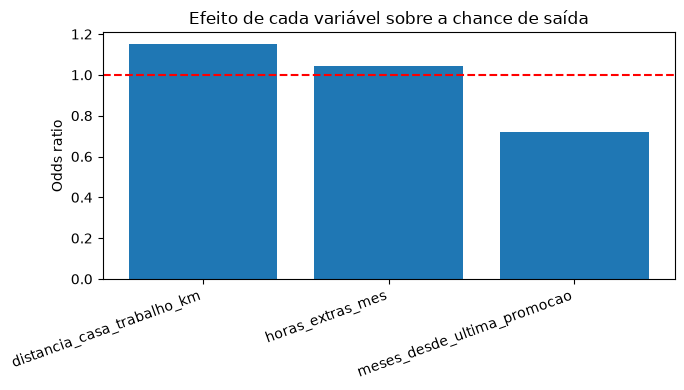

In [ ]:
dados9 = df[cols_9 + ['desligado']].dropna()
print('Linhas usadas:', len(dados9), 'de', len(df))

X9 = StandardScaler().fit_transform(dados9[cols_9])
y9 = dados9['desligado'].astype(int)
logit = LogisticRegression(class_weight='balanced', max_iter=1000).fit(X9, y9)

res = pd.DataFrame({'variavel': cols_9, 'odds_ratio': np.exp(logit.coef_[0]).round(3)})
print(res)   # odds ratio por 1 desvio-padrão; acima de 1 = aumenta a chance de sair

plt.figure(figsize=(7, 4))
plt.bar(res['variavel'], res['odds_ratio'])
plt.axhline(1, color='red', linestyle='--')
plt.ylabel('Odds ratio')
plt.title('Efeito de cada variável sobre a chance de saída')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

Linhas usadas: 2936 de 3028
              total  desligados  turnover_%
abaixo_media                               
False          1347         453        33.6
True           1589         528        33.2

Turnover (%) por faixa de salário relativo ao cargo:
faixa_salarial
Q1 (mais abaixo)    34.1
Q2                  33.2
Q3                  33.7
Q4 (mais acima)     32.7
Name: desligado, dtype: float64


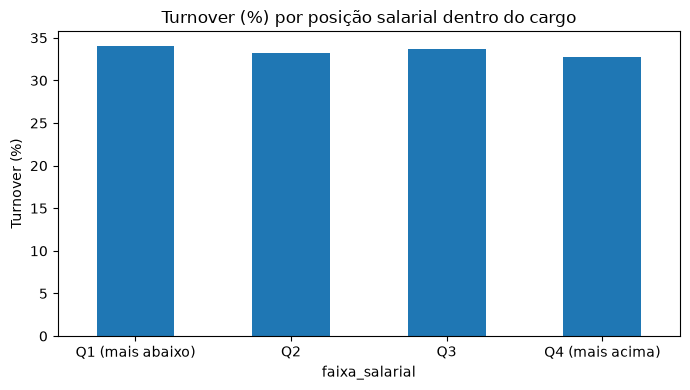

In [ ]:
base10 = df.dropna(subset=['salario_base']).copy()

# Só cargos com pelo menos 10 pessoas (média de cargo pequeno é pouco confiável)
tamanho_cargo = base10.groupby('cargo')['salario_base'].transform('count')
base10 = base10[tamanho_cargo >= 10].copy()
print('Linhas usadas:', len(base10), 'de', len(df))

base10['media_cargo'] = base10.groupby('cargo')['salario_base'].transform('mean')
base10['abaixo_media'] = base10['salario_base'] < base10['media_cargo']

abaixo = base10.groupby('abaixo_media')['desligado'].agg(total='count', desligados='sum')
abaixo['turnover_%'] = (abaixo['desligados'] / abaixo['total'] * 100).round(1)
print(abaixo)

# Versão gradual: posição salarial relativa dentro do cargo
base10['razao_salarial'] = base10['salario_base'] / base10['media_cargo']
base10['faixa_salarial'] = pd.qcut(
    base10['razao_salarial'], q=4,
    labels=['Q1 (mais abaixo)', 'Q2', 'Q3', 'Q4 (mais acima)']
)
faixas10 = base10.groupby('faixa_salarial', observed=True)['desligado'].mean() * 100
print('\nTurnover (%) por faixa de salário relativo ao cargo:')
print(faixas10.round(1))

faixas10.plot(kind='bar', figsize=(7, 4))
plt.title('Turnover (%) por posição salarial dentro do cargo')
plt.ylabel('Turnover (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()